In [4]:
import torch
print("torch ",torch.__version__)
try:
    import torchvision
except ImportError:  # no se usa en este notebook
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch import nn
from torchinfo import summary
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
import copy

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

torch  2.13.0
device: cpu


# Tabular data

* Easiest type of data to deal with, samples are already arranged as rows, as well as targets.
* Usually numerical features are used, if categorical features are considered, then an encoding such as One-Hot encoding is used to convert to numerical representation.
* Dense NNs are a good approach to deal with this type of data.
* We have already worked with these kind of NNs, here we simply show an example on how a network that takes multiple inputs is defined.

In [5]:
# Helpful regression visualization function
def visualize_true_vs_pred_regression(y_true,y_pred,target_name = "PE"):

    mae = round(np.mean(np.abs(y_true-y_pred)),2)

    fig= plt.figure(figsize=(14,7))
    p1 = max(max(y_pred), max(y_true))
    p2 = min(min(y_pred), min(y_true))
    plt.plot([p1, p2], [p1, p2], 'g-')
    plt.scatter(y_true,y_pred)
    plt.xlabel(f"Real value({target_name})",fontsize=20)
    plt.ylabel(f"Prediction({target_name})",fontsize=20)
    plt.title(f"Real value vs Predicted. MAE(Test)={mae:.2e}",fontdict={"fontsize":30})
    plt.show()

## Exercises 2.1

1. Using the CCPP dataset [(Combined Cycle Power Plant)](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant), build and train a dense NN that predicts the output power (PE) of the plant taking as input the other features in the table.
2. Using the CCPP dataset, now predict the plant's temperature (AT) using the other features (PE included).
3. Using Wine Quality dataset [(White wine)](https://www.kaggle.com/datasets/ruthgn/wine-quality-data-set-red-white-wine), build and train a dense NN that classifies the score a wine obtains taking as input its chemical properties. Before training the model, is there anything on the dataset we should care about? Are targets (score) evenly distributed? Apply weights in the [CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) function, assigning to each class a weight that is inversely proportional to the number of times it appears in the dataset. Does it improve performance compared to not using weighted classes?
4. Using Wine Quality dataset, now treat the problem as a regression problem, and instead of classifying a discrete score for each wine, predict a continuous score for each wine.

In [6]:
def make_loaders(X, y, task="regression", val_size=0.15, test_size=0.15, batch_size=128, stratify=None):
    """Split train/val/test + estandarización (fit solo con train). Devuelve loaders y objetos auxiliares."""
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=val_size+test_size, random_state=SEED,
                                                stratify=stratify)
    strat_tmp = y_tmp if stratify is not None else None
    if strat_tmp is not None and np.bincount(strat_tmp)[np.bincount(strat_tmp)>0].min() < 2:
        strat_tmp = None      # alguna clase (p.ej. la 9) tiene <2 muestras en val+test: no se puede estratificar
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=test_size/(val_size+test_size),
                                              random_state=SEED, stratify=strat_tmp)
    sx = StandardScaler().fit(X_tr)
    sy = None
    if task == "regression":               # el target también se estandariza (mejor condicionado)
        sy = StandardScaler().fit(y_tr.reshape(-1,1))
    def tt(Xa, ya):
        Xt = torch.tensor(sx.transform(Xa), dtype=torch.float32)
        if task == "regression":
            yt = torch.tensor(sy.transform(ya.reshape(-1,1)), dtype=torch.float32)
        else:
            yt = torch.tensor(ya, dtype=torch.long)
        return TensorDataset(Xt, yt)
    dl_tr = DataLoader(tt(X_tr,y_tr), batch_size=batch_size, shuffle=True)
    dl_va = DataLoader(tt(X_va,y_va), batch_size=1024)
    dl_te = DataLoader(tt(X_te,y_te), batch_size=1024)
    return dl_tr, dl_va, dl_te, sx, sy, (y_tr, y_va, y_te)

class MLP(nn.Module):
    def __init__(self, n_in, n_out, hidden=(64,64,32), p_drop=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev,h), nn.ReLU()]
            if p_drop>0: layers.append(nn.Dropout(p_drop))
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def fit(model, dl_tr, dl_va, loss_fn, epochs=100, lr=1e-3, weight_decay=0.0, verbose=True):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best, best_state, hist = float("inf"), None, {"train":[], "val":[]}
    for ep in range(epochs):
        model.train(); tot=n=0
        for xb,yb in dl_tr:
            xb,yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            tot += loss.item()*len(xb); n += len(xb)
        model.eval(); vt=vn=0
        with torch.no_grad():
            for xb,yb in dl_va:
                xb,yb = xb.to(device), yb.to(device)
                vt += loss_fn(model(xb), yb).item()*len(xb); vn += len(xb)
        hist["train"].append(tot/n); hist["val"].append(vt/vn)
        if hist["val"][-1] < best:
            best, best_state = hist["val"][-1], copy.deepcopy(model.state_dict())
        if verbose and (ep+1) % max(1,epochs//10) == 0:
            print(f"epoch {ep+1:3d} | train {hist['train'][-1]:.4f} | val {hist['val'][-1]:.4f}")
    model.load_state_dict(best_state)
    return hist

@torch.no_grad()
def predict(model, dl):
    model.eval()
    return torch.cat([model(xb.to(device)).cpu() for xb,_ in dl])

def plot_history(hist, title=""):
    plt.figure(figsize=(8,4)); plt.plot(hist["train"],label="train"); plt.plot(hist["val"],label="val")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(title); plt.legend(); plt.show()

## Exercise 2.1 - Predecir `PE` (potencia de salida) en CCPP

### Preparación de datos: ¡los 5 CSV son la misma tabla!

El dataset original de UCI viene como un Excel con 5 hojas, cada una con **las mismas 9568 filas en distinto orden**. Si concatenamos los cinco CSV sin más, tendríamos cada muestra repetida 5 veces y, al hacer el split aleatorio, **las mismas filas caerían a la vez en train y test** (fuga de datos → métricas de test falsamente optimistas). Por eso eliminamos duplicados tras concatenar.

In [7]:
ccpp = pd.concat([pd.read_csv(f"ccpp_{i}.csv") for i in range(1,6)], ignore_index=True)
print("Filas tras concatenar:", len(ccpp))
ccpp = ccpp.drop_duplicates().reset_index(drop=True)
print("Filas únicas:", len(ccpp), "(9568 filas originales; 41 de ellas tienen valores idénticos a otra fila y también se descartan)")
ccpp.describe().T

Filas tras concatenar: 47840
Filas únicas: 9527 (9568 filas originales; 41 de ellas tienen valores idénticos a otra fila y también se descartan)


,count,mean,std,min,25%,50%,75%,max
AT,9527.0,19.658225,7.444397,1.81,13.530,20.35,25.710,37.11
V,9527.0,54.293421,12.686309,25.36,41.740,52.08,66.510,81.56
AP,9527.0,1013.237084,5.940526,992.89,1009.085,1012.92,1017.200,1033.30
RH,9527.0,73.334951,14.607513,25.56,63.375,75.00,84.850,100.16
PE,9527.0,454.335910,17.039080,420.26,439.750,451.52,468.365,495.76


In [8]:
def run_ccpp(target, epochs=100, hidden=(64,64,32)):
    feats = [c for c in ccpp.columns if c != target]
    X, y = ccpp[feats].values, ccpp[target].values
    dl_tr, dl_va, dl_te, sx, sy, (y_tr,y_va,y_te) = make_loaders(X, y, "regression")
    model = MLP(len(feats), 1, hidden)
    print("Entradas:", feats, "-> salida:", target)
    hist = fit(model, dl_tr, dl_va, nn.MSELoss(), epochs=epochs)
    plot_history(hist, f"CCPP - {target}")
    pred = sy.inverse_transform(predict(model, dl_te).numpy()).ravel()   # de vuelta a unidades reales
    # baseline: predecir siempre la media del train
    mae_base = np.mean(np.abs(y_te - y_tr.mean()))
    print(f"MAE test = {np.mean(np.abs(y_te-pred)):.3f} | RMSE = {np.sqrt(np.mean((y_te-pred)**2)):.3f} "
          f"| R2 = {1-np.sum((y_te-pred)**2)/np.sum((y_te-y_te.mean())**2):.4f} | baseline(media) MAE = {mae_base:.3f}")
    visualize_true_vs_pred_regression(y_te, pred, target)
    return model, y_te, pred

feats_pe = ["AT","V","AP","RH"]
summary(MLP(4,1), input_size=(1,4))

Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      [1, 1]                    --
├─Sequential: 1-1                        [1, 1]                    --
│    └─Linear: 2-1                       [1, 64]                   320
│    └─ReLU: 2-2                         [1, 64]                   --
│    └─Linear: 2-3                       [1, 64]                   4,160
│    └─ReLU: 2-4                         [1, 64]                   --
│    └─Linear: 2-5                       [1, 32]                   2,080
│    └─ReLU: 2-6                         [1, 32]                   --
│    └─Linear: 2-7                       [1, 1]                    33
Total params: 6,593
Trainable params: 6,593
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.01
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.03
Estimated Total Size (MB): 0.03

Entradas: ['AT', 'V', 'AP', 'RH'] -> salida: PE
epoch  10 | train 0.0566 | val 0.0616
epoch  20 | train 0.0544 | val 0.0595
epoch  30 | train 0.0522 | val 0.0579
epoch  40 | train 0.0515 | val 0.0613
epoch  50 | train 0.0500 | val 0.0576
epoch  60 | train 0.0487 | val 0.0570
epoch  70 | train 0.0494 | val 0.0558
epoch  80 | train 0.0491 | val 0.0557
epoch  90 | train 0.0476 | val 0.0554
epoch 100 | train 0.0462 | val 0.0561


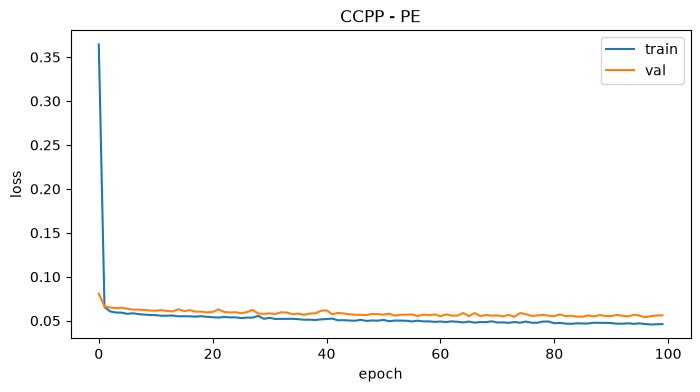

MAE test = 3.013 | RMSE = 4.079 | R2 = 0.9434 | baseline(media) MAE = 14.880


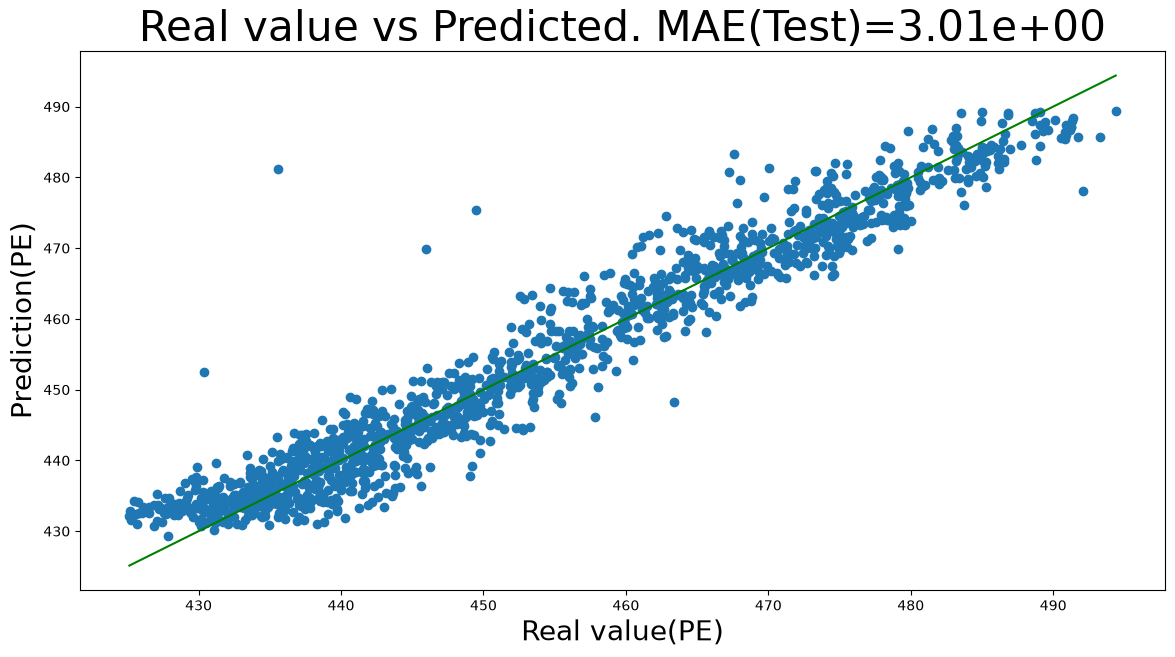

In [9]:
model_pe, y_te_pe, pred_pe = run_ccpp("PE")

## Exercise 2.2 - Predecir `AT` (temperatura) con el resto de variables (PE incluida)

Mismo pipeline, cambiando solo el objetivo; ahora las entradas son `V, AP, RH, PE`.

Entradas: ['V', 'AP', 'RH', 'PE'] -> salida: AT
epoch  10 | train 0.0515 | val 0.0535
epoch  20 | train 0.0489 | val 0.0514
epoch  30 | train 0.0467 | val 0.0511
epoch  40 | train 0.0450 | val 0.0502
epoch  50 | train 0.0445 | val 0.0499
epoch  60 | train 0.0431 | val 0.0479
epoch  70 | train 0.0425 | val 0.0479
epoch  80 | train 0.0422 | val 0.0474
epoch  90 | train 0.0406 | val 0.0465
epoch 100 | train 0.0400 | val 0.0503


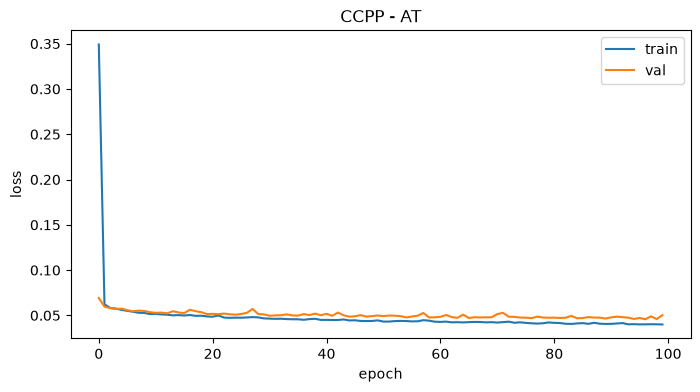

MAE test = 1.229 | RMSE = 1.643 | R2 = 0.9520 | baseline(media) MAE = 6.494


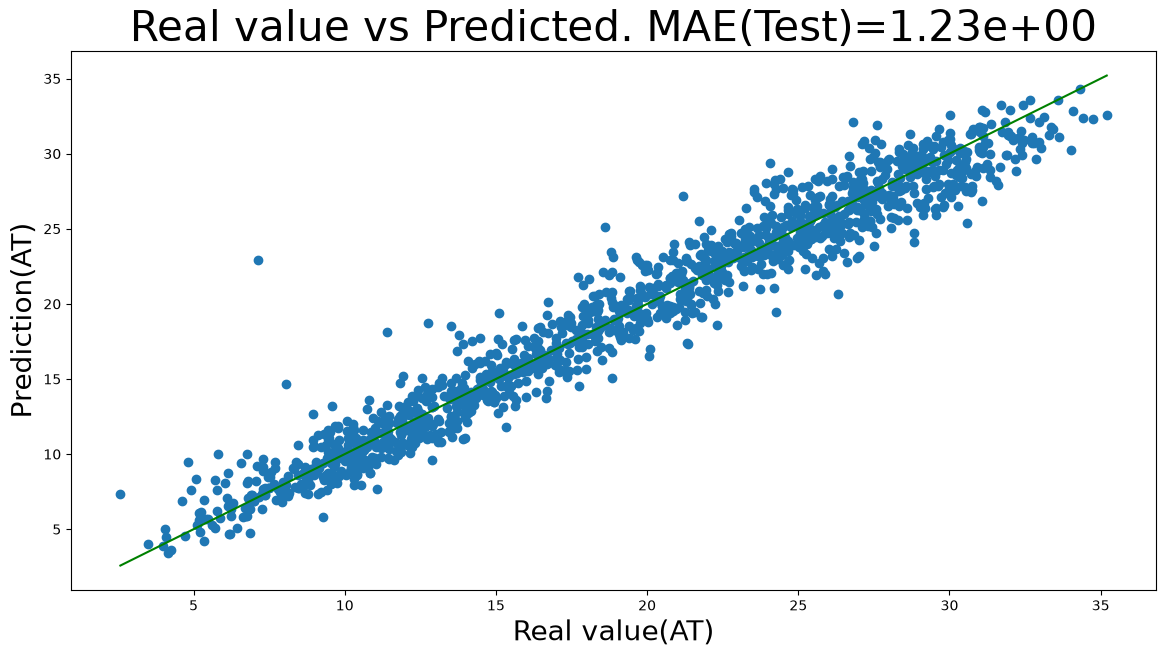

In [10]:
model_at, y_te_at, pred_at = run_ccpp("AT")

## Exercise 2.3 - Wine Quality (white): clasificación de la puntuación

### Antes de entrenar: ¿qué hay que revisar?

1. **Duplicados**: el dataset de vino blanco tiene filas repetidas. Si no se eliminan, pueden aparecer en train y en test a la vez.
2. **Distribución de las clases**: la calidad está muy desbalanceada (casi todo son 5, 6 y 7; las clases 3, 4, 8 y 9 tienen muy pocas muestras).
3. **Escalado**: las variables tienen rangos muy distintos (`total sulfur dioxide` ~ 100, `chlorides` ~ 0.05), así que las estandarizamos.
4. Las etiquetas deben ser enteros `0..C-1` para `CrossEntropyLoss`, así que restamos el mínimo (3).

Filas: 4898 | duplicadas: 937
Filas tras eliminar duplicados: 3961
quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64


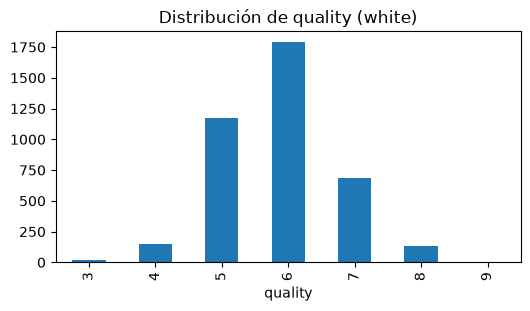

In [11]:
wine = pd.read_csv("winequality-white.csv", sep=";")
print("Filas:", len(wine), "| duplicadas:", wine.duplicated().sum())
wine = wine.drop_duplicates().reset_index(drop=True)
print("Filas tras eliminar duplicados:", len(wine))
counts = wine["quality"].value_counts().sort_index()
print(counts)
counts.plot.bar(figsize=(6,3), title="Distribución de quality (white)"); plt.show()

In [12]:
X_w = wine.drop(columns="quality").values
y_w = wine["quality"].values
classes = np.sort(np.unique(y_w)); n_classes = len(classes)
y_cls = y_w - classes.min()                       # 3..9 -> 0..6

def run_wine_cls(weighted, epochs=150, seed=SEED):
    torch.manual_seed(seed)
    dl_tr, dl_va, dl_te, sx, _, (y_tr,y_va,y_te) = make_loaders(X_w, y_cls, "classification", stratify=y_cls)
    if weighted:
        cnt = np.bincount(y_tr, minlength=n_classes)
        w = len(y_tr) / (n_classes * cnt)                 # inversamente proporcional a la frecuencia
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
        if seed == SEED: print("pesos por clase:", np.round(w,2))
    else:
        loss_fn = nn.CrossEntropyLoss()
    model = MLP(X_w.shape[1], n_classes, (64,64,32), p_drop=0.2)
    hist = fit(model, dl_tr, dl_va, loss_fn, epochs=epochs, verbose=False)
    # la pérdida de validación se calcula con la misma loss_fn (ponderada o no)
    pred = predict(model, dl_te).argmax(1).numpy()
    res = dict(acc=accuracy_score(y_te,pred), bal_acc=balanced_accuracy_score(y_te,pred),
               f1_macro=f1_score(y_te,pred,average="macro",zero_division=0))
    return res, y_te, pred, hist

res_nw, y_te_c, pred_nw, h_nw = run_wine_cls(weighted=False)
res_w,  _,      pred_w,  h_w  = run_wine_cls(weighted=True)
comp = pd.DataFrame({"sin pesos":res_nw, "con pesos":res_w}).T.round(3)
comp

pesos por clase: [28.29  3.7   0.48  0.32  0.82  4.3  99.  ]


c:\Users\maren\.conda\envs\datamining_3\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,acc,bal_acc,f1_macro
sin pesos,0.56,0.302,0.314
con pesos,0.39,0.393,0.248


In [13]:
rows = []
for s in range(5):
    for wtd in (False, True):
        r,_,_,_ = run_wine_cls(weighted=wtd, seed=s)
        rows.append(dict(weighted=wtd, seed=s, **r))
df_seeds = pd.DataFrame(rows)
df_seeds.groupby("weighted")[["acc","bal_acc","f1_macro"]].agg(["mean","std"]).round(3)

c:\Users\maren\.conda\envs\datamining_3\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\maren\.conda\envs\datamining_3\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\maren\.conda\envs\datamining_3\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\maren\.conda\envs\datamining_3\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\maren\.conda\envs\datamining_3\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pre

acc        bal_acc        f1_macro       
           mean    std    mean    std     mean    std
weighted                                             
False     0.559  0.008   0.294  0.007    0.305  0.009
True      0.339  0.016   0.422  0.082    0.227  0.013

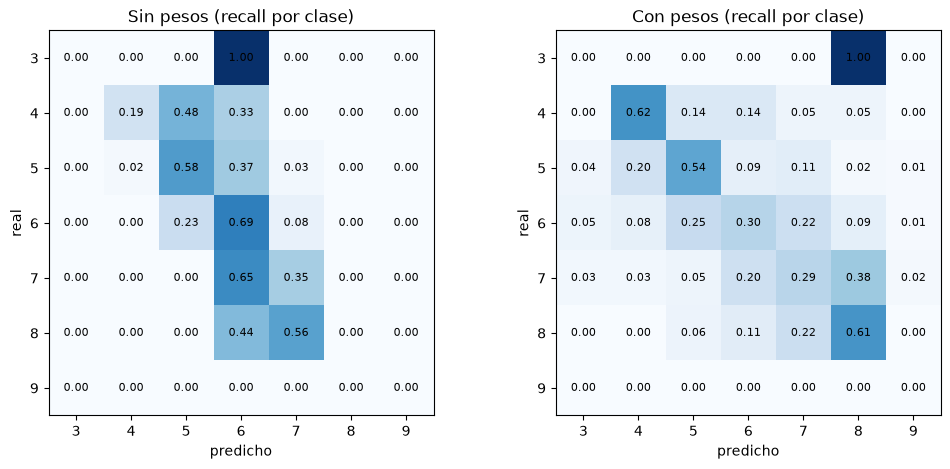

In [14]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
for a,(p,t) in zip(ax, [(pred_nw,"Sin pesos"),(pred_w,"Con pesos")]):
    cm = confusion_matrix(y_te_c, p, labels=range(n_classes))
    cm = cm / cm.sum(1, keepdims=True).clip(min=1)          # recall por clase (filas normalizadas)
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1); a.set_title(f"{t} (recall por clase)")
    a.set_xticks(range(n_classes)); a.set_xticklabels(classes); a.set_yticks(range(n_classes)); a.set_yticklabels(classes)
    a.set_xlabel("predicho"); a.set_ylabel("real")
    for i in range(n_classes):
        for j in range(n_classes): a.text(j,i,f"{cm[i,j]:.2f}",ha="center",va="center",fontsize=8)
plt.show()

#### ¿Mejora el rendimiento usando pesos?

Resultados en test (media de 5 semillas, mismo split):

| | Accuracy | Balanced accuracy | F1 macro |
|---|---|---|---|
| Sin pesos | 0.559 | 0.294 | 0.305 |
| Con pesos | 0.339 | 0.422 | 0.227 |

**No hay una mejora clara: depende de la métrica.**

* Sin pesos, la red aprende sobre todo las clases mayoritarias (5, 6 y 7). Tiene buena *accuracy* pero ignora casi por completo las clases 3, 4, 8 y 9.
* Con pesos (inversamente proporcionales a la frecuencia), el *recall* de las clases minoritarias sube y por eso mejora la *balanced accuracy* (0.29 → 0.42). A cambio, se equivoca mucho más en las clases grandes, y tanto la *accuracy* (0.56 → 0.34) como el F1 macro (0.31 → 0.23) empeoran.
* Los pesos extremos (≈99 para la clase 9, que solo tiene 5 muestras en todo el dataset) hacen el entrenamiento inestable (la desviación típica de la balanced accuracy entre semillas es alta) y las clases 3 y 9 tienen tan pocas muestras en test que sus métricas son casi anecdóticas.
* Conclusión: usar pesos solo compensa si nos importa detectar las calidades raras; si el objetivo es acertar la mayor cantidad de vinos, es mejor no ponderar. Alternativas: pesos menos agresivos (p. ej. raíz de la inversa), sobremuestreo, o agrupar las clases extremas.

## Exercise 2.4 - Wine Quality como regresión

Ahora `quality` se trata como un valor continuo. Usamos MSE como pérdida y, para poder compararlo con la clasificación, también redondeamos la predicción al entero más cercano y calculamos la exactitud.

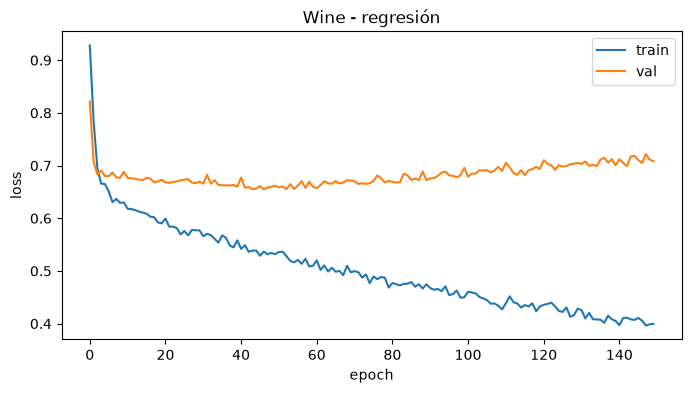

MAE test = 0.566 | RMSE = 0.722 | baseline(media) MAE = 0.672
Accuracy al redondear = 0.521 | balanced acc = 0.259


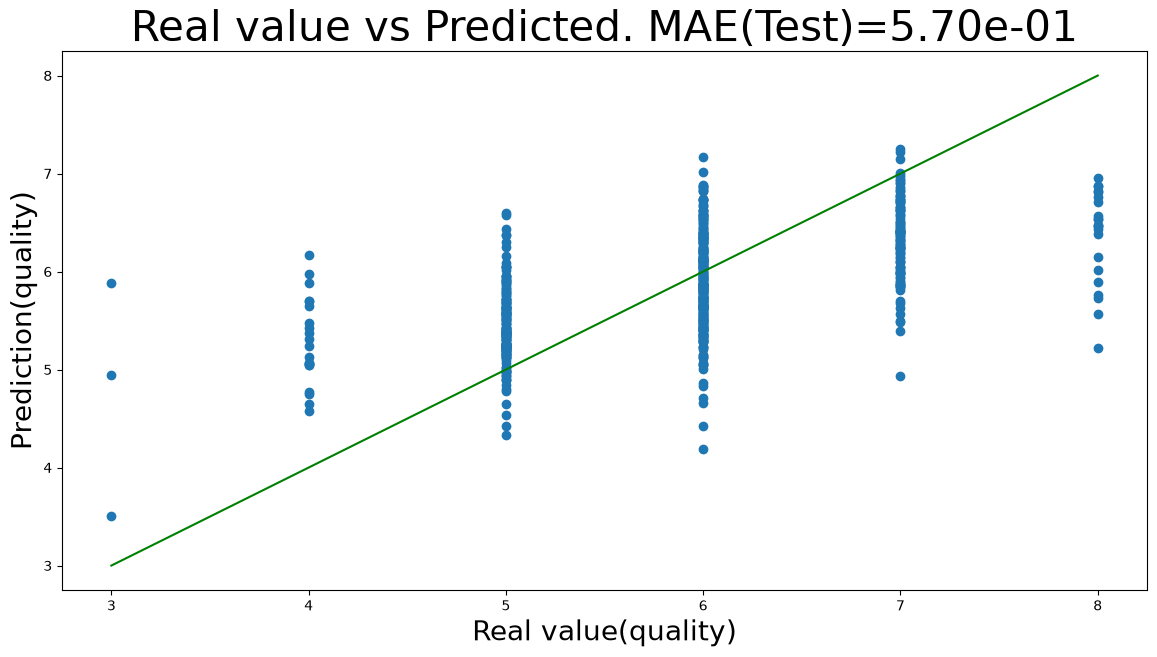

In [15]:
torch.manual_seed(SEED)
dl_tr, dl_va, dl_te, sx, sy, (y_tr,y_va,y_te) = make_loaders(X_w, y_w.astype(float), "regression")
model_wr = MLP(X_w.shape[1], 1, (64,64,32), p_drop=0.1)
hist = fit(model_wr, dl_tr, dl_va, nn.MSELoss(), epochs=150, verbose=False)
plot_history(hist, "Wine - regresión")
pred_wr = sy.inverse_transform(predict(model_wr, dl_te).numpy()).ravel()
mae = np.mean(np.abs(y_te-pred_wr))
print(f"MAE test = {mae:.3f} | RMSE = {np.sqrt(np.mean((y_te-pred_wr)**2)):.3f} | baseline(media) MAE = {np.mean(np.abs(y_te-y_tr.mean())):.3f}")
pred_round = np.clip(np.rint(pred_wr), classes.min(), classes.max())
print(f"Accuracy al redondear = {accuracy_score(y_te, pred_round):.3f} | balanced acc = {balanced_accuracy_score(y_te, pred_round):.3f}")
visualize_true_vs_pred_regression(y_te, pred_wr, "quality")

#### Conclusiones

* La regresión obtiene un MAE de test de ≈ 0.57 puntos de calidad, frente a ≈ 0.67 de predecir siempre la media: mejora modesta, lo que indica que las propiedades químicas explican solo en parte la puntuación (que además es una valoración subjetiva).
* Al redondear a entero, la *accuracy* (≈ 0.52) es algo menor que la del clasificador sin pesos (≈ 0.56) y la balanced accuracy es baja (≈ 0.26): el modelo de regresión tiende a "encogerse" hacia la media y casi nunca predice 3, 4, 8 o 9.
* La ventaja de la regresión es que respeta el orden de las clases (equivocarse por 1 punto es menos grave que por 3), algo que la entropía cruzada no tiene en cuenta; por eso el MAE es una métrica más informativa aquí que la accuracy.

**Resumen de los cuatro ejercicios:** en CCPP el modelo es muy bueno (R² ≈ 0.94 para `PE` con MAE ≈ 3.0 MW y R² ≈ 0.95 para `AT` con MAE ≈ 1.2 °C, frente a baselines de 14.9 y 6.5), mientras que en Wine Quality el problema es intrínsecamente más difícil por el ruido de las etiquetas y el fuerte desbalanceo.